# Dataset audit

MASSIVE, en-US / fr-FR / ar-SA. Run `python -m src.data.download_massive` from the repo root first.

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# works from the repo root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data" / "massive"
LOCALES = ["en-US", "fr-FR", "ar-SA"]
SPLITS = ["train", "dev", "test"]


def read_jsonl(path: Path) -> list[dict]:
    with path.open(encoding="utf-8") as f:
        return [json.loads(line) for line in f]


df = pd.DataFrame([
    row
    for loc in LOCALES
    for split in SPLITS
    for row in read_jsonl(DATA_DIR / loc / f"{split}.jsonl")
])
df.head()

,id,locale,split,scenario,intent,utt,annot_utt
0,1,en-US,train,alarm,alarm_set,wake me up at nine am on friday,wake me up at [time : nine am] on [date : friday]
1,2,en-US,train,alarm,alarm_set,set an alarm for two hours from now,set an alarm for [time : two hours from now]
2,4,en-US,train,audio,audio_volume_mute,olly quiet,olly quiet
3,5,en-US,train,audio,audio_volume_mute,stop,stop
4,6,en-US,train,audio,audio_volume_mute,olly pause for ten seconds,olly pause for [time : ten seconds]


MASSIVE is parallel (same utterances translated), so split sizes should match across locales.

In [2]:
sizes = df.pivot_table(index="locale", columns="split", values="id", aggfunc="count")
sizes = sizes.loc[LOCALES, SPLITS]
sizes["total"] = sizes.sum(axis=1)
sizes

split,train,dev,test,total
locale,,,,
en-US,11514,2033,2974,16521
fr-FR,11514,2033,2974,16521
ar-SA,11514,2033,2974,16521


Lengths in whitespace tokens and in characters. Whitespace tokens undercount Arabic, where clitics like و and ال are attached to the word.

In [3]:
df["n_tokens"] = df["utt"].str.split().str.len()
df["n_chars"] = df["utt"].str.len()

length_stats = (
    df.groupby("locale")[["n_tokens", "n_chars"]]
    .describe(percentiles=[0.5, 0.95, 0.99])
    .loc[LOCALES]
    .round(1)
)
length_stats

n_tokens                                        n_chars              \
          count mean  std  min  50%   95%   99%   max    count  mean   std   
locale                                                                       
en-US   16521.0  6.9  3.3  1.0  6.0  13.0  17.0  61.0  16521.0  34.9  16.7   
fr-FR   16521.0  7.4  3.5  1.0  7.0  14.0  18.0  76.0  16521.0  42.6  20.0   
ar-SA   16521.0  5.2  2.7  1.0  5.0  10.0  13.0  42.0  16521.0  26.9  14.3   

                                       
        min   50%   95%    99%    max  
locale                                 
en-US   2.0  32.0  65.0   87.0  365.0  
fr-FR   2.0  40.0  79.0  104.0  479.0  
ar-SA   1.0  25.0  53.0   70.0  247.0

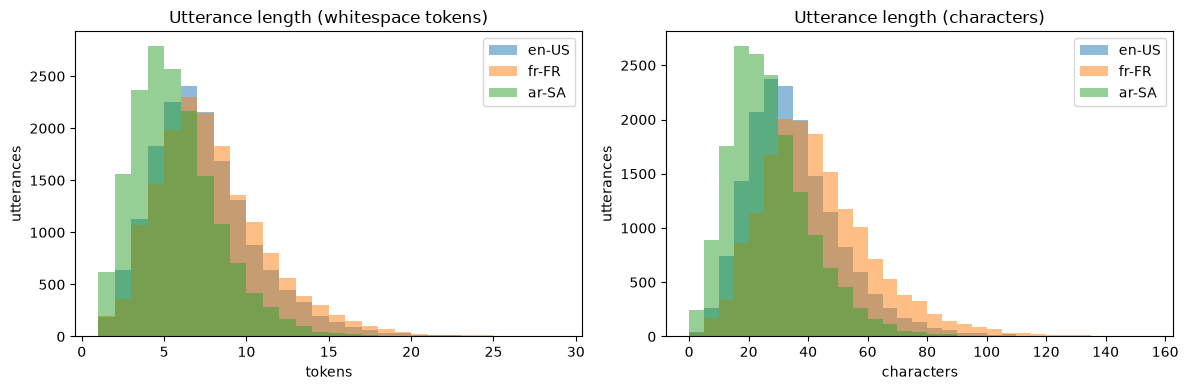

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for loc in LOCALES:
    sub = df[df["locale"] == loc]
    axes[0].hist(sub["n_tokens"], bins=range(1, 30), alpha=0.5, label=loc)
    axes[1].hist(sub["n_chars"], bins=range(0, 160, 5), alpha=0.5, label=loc)
axes[0].set(title="Utterance length (whitespace tokens)", xlabel="tokens", ylabel="utterances")
axes[1].set(title="Utterance length (characters)", xlabel="characters", ylabel="utterances")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

Slots are inline in `annot_utt` as `[slot_name : value]`. Each slot becomes one argument; no slots gives a call like `alarm_query()`.

In [5]:
SLOT_RE = re.compile(r"\[\s*([^\[\]:]+?)\s*:\s*([^\[\]]*?)\s*\]")

df["slots"] = df["annot_utt"].apply(SLOT_RE.findall)  # list of (name, value)
df["n_slots"] = df["slots"].str.len()

# each '[' should match exactly one slot
unmatched = df[df["annot_utt"].str.count(r"\[") != df["n_slots"]]
print("utterances where the regex missed a slot:", len(unmatched))

df[["annot_utt", "slots"]].head()

utterances where the regex missed a slot: 0


,annot_utt,slots
0,wake me up at [time : nine am] on [date : friday],"[(time, nine am), (date, friday)]"
1,set an alarm for [time : two hours from now],"[(time, two hours from now)]"
2,olly quiet,[]
3,stop,[]
4,olly pause for [time : ten seconds],"[(time, ten seconds)]"


In [6]:
slot_dist = pd.crosstab(df["locale"], df["n_slots"], normalize="index").loc[LOCALES]
summary = pd.DataFrame({
    "mean_slots": df.groupby("locale")["n_slots"].mean(),
    "max_slots": df.groupby("locale")["n_slots"].max(),
    "pct_no_slot": df.groupby("locale")["n_slots"].apply(lambda s: (s == 0).mean() * 100),
    "n_slot_types": df.explode("slots").dropna(subset=["slots"])
        .assign(name=lambda d: d["slots"].str[0]).groupby("locale")["name"].nunique(),
}).loc[LOCALES].round(2)
display(summary)
(slot_dist * 100).round(1)  # % of utterances with k slots

,mean_slots,max_slots,pct_no_slot,n_slot_types
locale,,,,
en-US,0.98,7,32.66,55
fr-FR,0.96,7,34.24,55
ar-SA,0.97,7,32.74,55


n_slots,0,1,2,3,4,5,6,7
locale,,,,,,,,
en-US,32.7,44.2,17.3,4.5,1.2,0.1,0.0,0.0
fr-FR,34.2,43.3,16.7,4.4,1.2,0.1,0.0,0.0
ar-SA,32.7,44.5,17.2,4.4,1.1,0.1,0.0,0.0


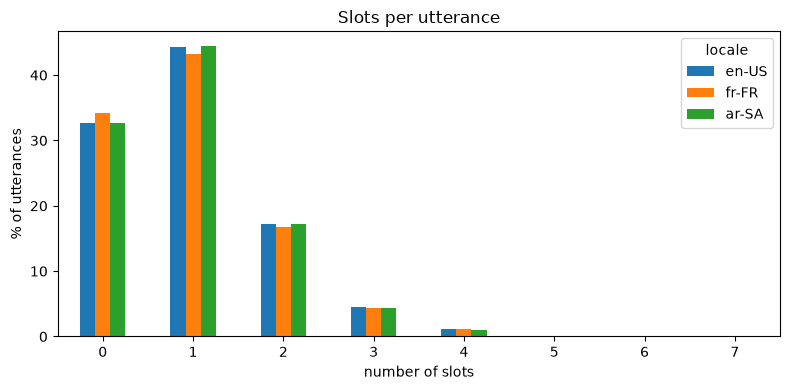

In [7]:
ax = (slot_dist.T * 100).plot.bar(figsize=(8, 4), rot=0)
ax.set(title="Slots per utterance", xlabel="number of slots", ylabel="% of utterances")
plt.tight_layout()
plt.show()

Intent counts on train. The intent label is the function name.

In [8]:
train = df[df["split"] == "train"]
print("number of intents per locale:", train.groupby("locale")["intent"].nunique().to_dict())

top20 = {loc: train[train["locale"] == loc]["intent"].value_counts().head(20) for loc in LOCALES}

pd.concat(
    {loc: s.rename_axis("intent").reset_index(name="count") for loc, s in top20.items()},
    axis=1,
).set_axis(range(1, 21))

number of intents per locale: {'ar-SA': 60, 'en-US': 60, 'fr-FR': 60}


en-US                        fr-FR        \
                   intent count                 intent count   
1            calendar_set   810           calendar_set   810   
2              play_music   639             play_music   639   
3           weather_query   573          weather_query   573   
4          calendar_query   566         calendar_query   566   
5          general_quirky   555         general_quirky   555   
6              qa_factoid   544             qa_factoid   544   
7              news_query   503             news_query   503   
8             email_query   418            email_query   418   
9         email_sendemail   354        email_sendemail   354   
10         datetime_query   350         datetime_query   350   
11        calendar_remove   312        calendar_remove   312   
12             play_radio   283             play_radio   283   
13            social_post   283            social_post   283   
14          qa_definition   267          qa_definition   267   
15        transport_query   227        transport_query   227   
16         cooking_recipe   207         cooking_recipe   207   
17            lists_query   198            lists_query   198   
18          play_podcasts   193          play_podcasts   193   
19  recommendation_events   190  recommendation_events   190   
20              alarm_set   182              alarm_set   182   

                    ar-SA        
                   intent count  
1            calendar_set   810  
2              play_music   639  
3           weather_query   573  
4          calendar_query   566  
5          general_quirky   555  
6              qa_factoid   544  
7              news_query   503  
8             email_query   418  
9         email_sendemail   354  
10         datetime_query   350  
11        calendar_remove   312  
12             play_radio   283  
13            social_post   283  
14          qa_definition   267  
15        transport_query   227  
16         cooking_recipe   207  
17            lists_query   198  
18          play_podcasts   193  
19  recommendation_events   190  
20              alarm_set   182

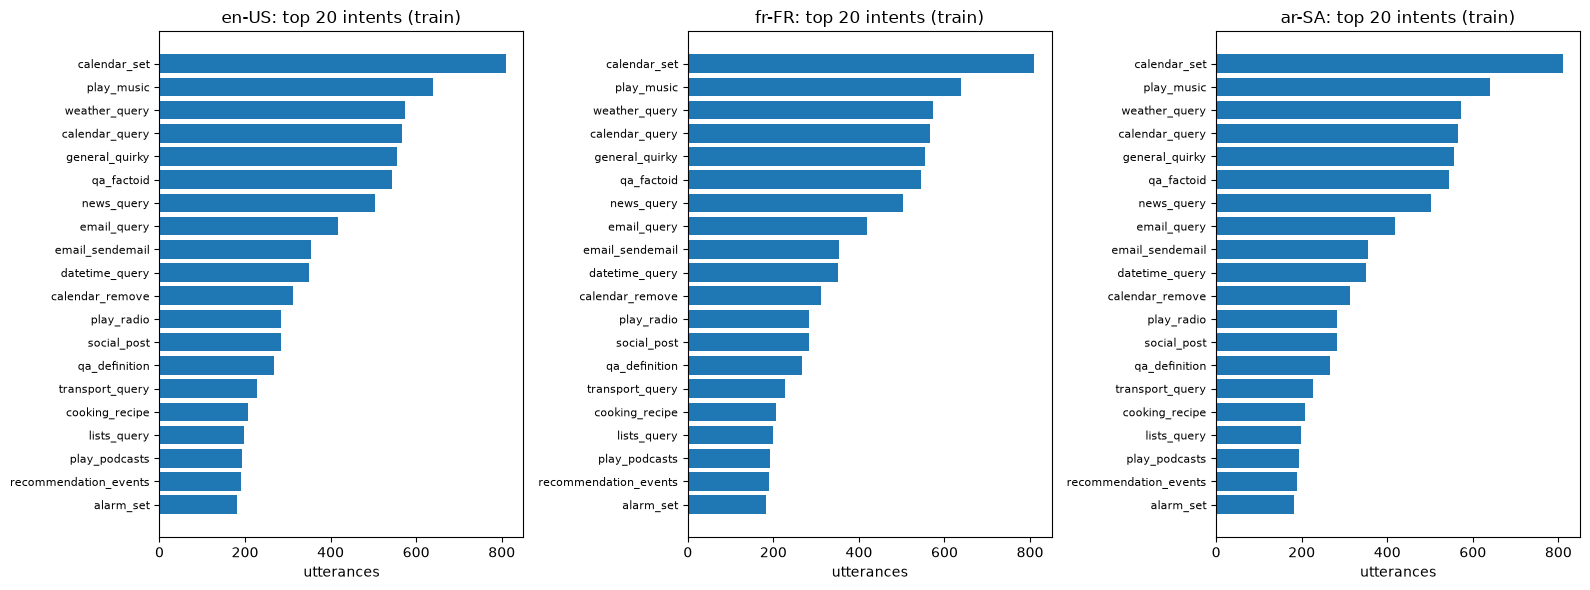

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharex=True)
for ax, loc in zip(axes, LOCALES):
    s = top20[loc][::-1]  # largest at the top
    ax.barh(s.index, s.values)
    ax.set(title=f"{loc}: top 20 intents (train)", xlabel="utterances")
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

In [10]:
train[train["locale"] == "en-US"]["intent"].value_counts().tail(5)

intent
general_greet         25
iot_hue_lighton       22
audio_volume_other    18
music_dislikeness     14
cooking_query          4
Name: count, dtype: int64

In [11]:
df.groupby("locale")["utt"].apply(lambda s: s.str.contains(r"\bolly\b", case=False).sum()).loc[LOCALES]

locale
en-US    534
fr-FR    526
ar-SA    262
Name: utt, dtype: int64

## Takeaways

- 11,514 / 2,033 / 2,974 utterances (train / dev / test) per language, 16,521 total. Same in all three locales since MASSIVE is parallel.
- 99th percentile length is 17 tokens in EN, 18 in FR, 13 in AR (87, 104 and 70 characters). The longest is 76 tokens (FR). I'll use max source length = 32 tokens and truncate the few longer ones.
- Arabic looks shorter (mean 5.2 tokens vs 6.9 EN and 7.4 FR) because clitics are attached to words. A word-level Arabic vocabulary will be larger and sparser, so subword tokenization is worth comparing there.
- About a third of utterances have no slots (32.7% EN, 34.2% FR, 32.7% AR) and become calls with no arguments. 44% have one slot, about 1.3% have 4 or more, max is 7.
- 60 intents and 55 slot types in every locale. The slot regex missed 0 slots, so the converter can reuse it.
- Intents are very unbalanced: `calendar_set` has 810 train examples, `cooking_query` only 4 (about 200x fewer). `music_dislikeness` (14), `audio_volume_other` (18), `iot_hue_lighton` (22) and `general_greet` (25) are also rare. I'll report per-intent and macro-averaged scores next to exact match, and I expect errors on intents with fewer than ~20 examples.
- "olly" (the wake word) is in 534 EN, 526 FR and 262 AR utterances (about 3.2%, 3.2% and 1.6%). Arabic also writes it as أولي sometimes, which the count skips because that word also means "primary". I'll keep it in the input, since the model has to handle it anyway.
- `general_quirky` (555) and `qa_factoid` (544) are not real tools, so the agent needs a fallback for them.